In [48]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [49]:
import catboost

In [50]:
df = pd.read_csv("Data/data_kern_ratios_06_10.csv")

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3028 entries, 0 to 3027
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3028 non-null   float64
 1   Al                        3028 non-null   float64
 2   Si                        3028 non-null   float64
 3   P                         3028 non-null   float64
 4   S                         3028 non-null   float64
 5   K                         3028 non-null   float64
 6   Ca                        3028 non-null   float64
 7   Ti                        3028 non-null   float64
 8   Mn                        3028 non-null   float64
 9   Fe                        3028 non-null   float64
 10  Ni                        3028 non-null   float64
 11  Cu                        3028 non-null   float64
 12  Zn                        3028 non-null   float64
 13  Se                        3028 non-null   float64
 14  Rb      

In [52]:
df['Strat'].value_counts().sort_index()

Strat
0     448
1     156
2     182
3     267
4     233
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по относительным параметрам на основе элементов и соотношений на новом датасете 05.10 с новой разметкой**

In [53]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

**Расчет скользящих градиентов Δxi = xi - xi-1 по каждой скважине (сортировка по Depth)**

In [54]:
# Сортировка df по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted[grad_col] = df_sorted.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

# Исходный порядок
df = df_sorted

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 49


In [55]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [56]:
features = ['dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9949
F1 macro (val):   0.4894
Gap (train-val):  0.5056

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.8280    0.6111    0.7032       126
           1     0.4286    0.5294    0.4737        51
           2     0.2105    0.1739    0.1905        46
           3     0.4787    0.6250    0.5422        72
           4     0.4107    0.5111    0.4554        45
           5     0.2000    0.5000    0.2857         6
           6     0.3929    0.5238    0.4490        21
           7     0.6429    0.3214    0.4286        56
           8     0.3571    0.5102    0.4202        49
           9     0.7024    0.6860    0.6941        86
          10     0.7500    0.5538    0.6372        65
          11     0.5333    0.6667    0.5926        24

    accuracy                    

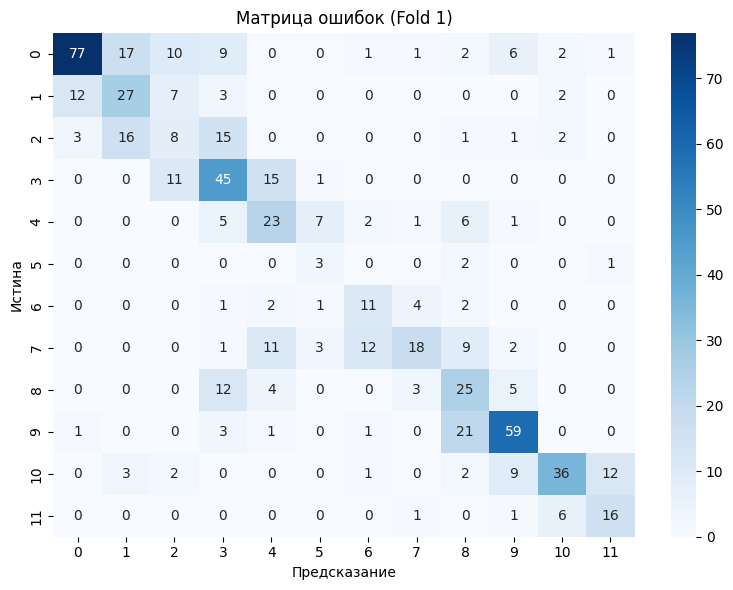

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9977
F1 macro (val):   0.5982
Gap (train-val):  0.3996

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9266    0.9018    0.9140       112
           1     0.2727    0.6429    0.3830        14
           2     0.7857    0.4783    0.5946        46
           3     0.7733    0.7532    0.7632        77
           4     0.6375    0.7500    0.6892        68
           5     0.5714    0.2667    0.3636        45
           6     0.4615    0.4444    0.4528        27
           7     0.4333    0.4194    0.4262        31
           8     0.5300    0.6235    0.5730        85
           9     0.7524    0.7117    0.7315       111
          10     0.4583    0.5000    0.4783        22
          11     0.7037    0.9500    0.8085        20

    accuracy                    

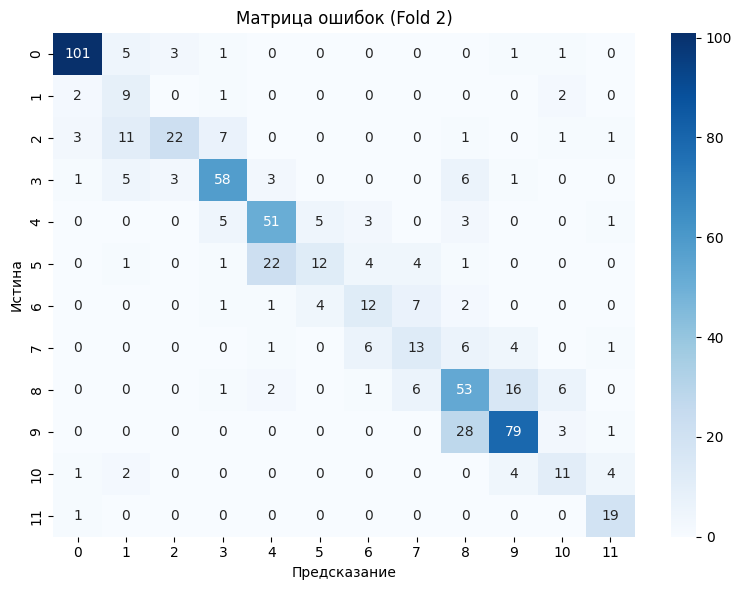

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9976
F1 macro (val):   0.5726
Gap (train-val):  0.4250

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8633    0.9600    0.9091       125
           1     0.6190    0.3611    0.4561        36
           2     0.7000    0.6562    0.6774        32
           3     0.5476    0.7667    0.6389        30
           4     0.5500    0.6111    0.5789        36
           5     0.4286    0.1667    0.2400        36
           6     0.3636    0.2424    0.2909        33
           7     0.3714    0.3250    0.3467        40
           8     0.5625    0.5114    0.5357        88
           9     0.5648    0.7821    0.6559        78
          10     0.7857    0.7333    0.7586        45
          11     0.6923    0.9000    0.7826        20

    accuracy                    

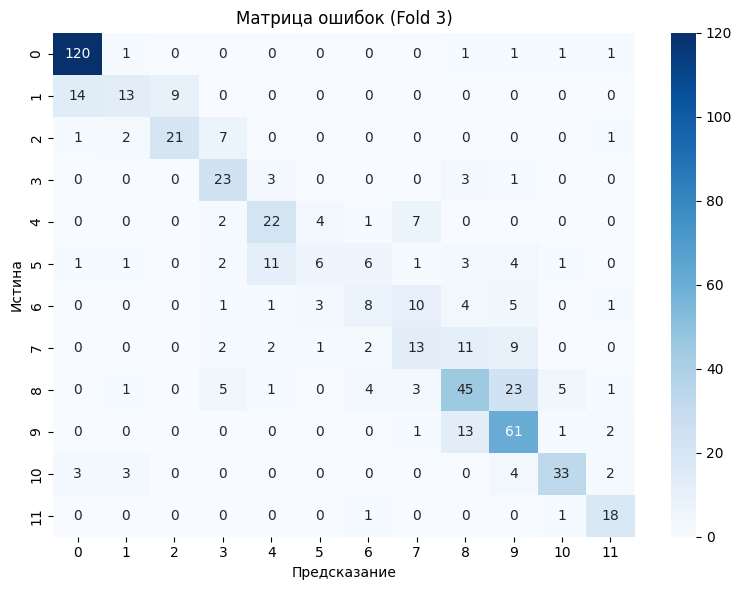

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9964
F1 macro (val):   0.5516
Gap (train-val):  0.4449

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.7917    0.9828    0.8769        58
           1     0.5882    0.2564    0.3571        39
           2     0.4468    0.6000    0.5122        35
           3     0.6444    0.5577    0.5979        52
           4     0.6735    0.5893    0.6286        56
           5     0.3750    0.2500    0.3000        24
           6     0.5385    0.5000    0.5185        28
           7     0.4286    0.2045    0.2769        44
           8     0.3103    0.2857    0.2975        63
           9     0.5741    0.8493    0.6851        73
          10     0.7183    0.9107    0.8031        56
          11     0.7879    0.7429    0.7647        35

    accuracy                    

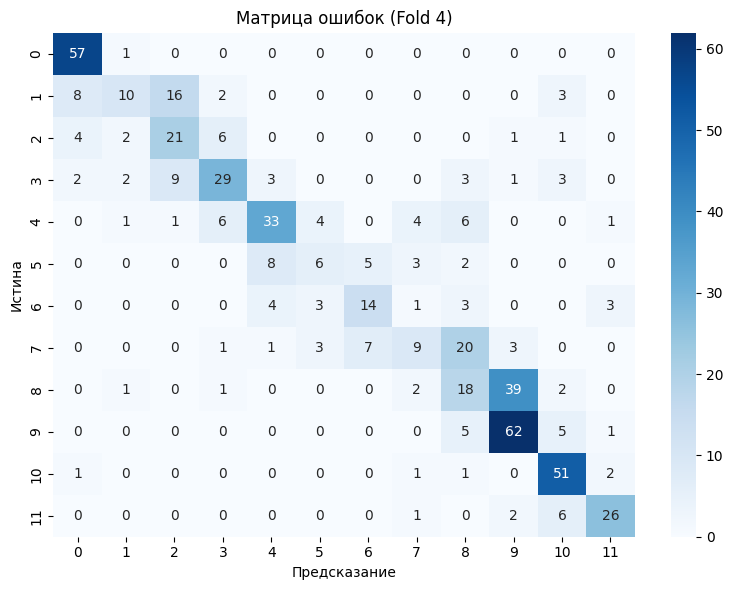

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9971
F1 macro (val):   0.4738
Gap (train-val):  0.5233

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.3662    0.9630    0.5306        27
           1     0.5833    0.4375    0.5000        16
           2     0.6667    0.5217    0.5854        23
           3     0.6316    0.6667    0.6486        36
           4     0.3902    0.5714    0.4638        28
           5     0.0556    0.0455    0.0500        22
           6     0.5000    0.3636    0.4211        22
           7     0.2593    0.3043    0.2800        23
           8     0.5405    0.5000    0.5195        80
           9     0.5734    0.6777    0.6212       121
          10     0.6582    0.6582    0.6582        79
          11     0.9167    0.2619    0.4074        84

    accuracy                    

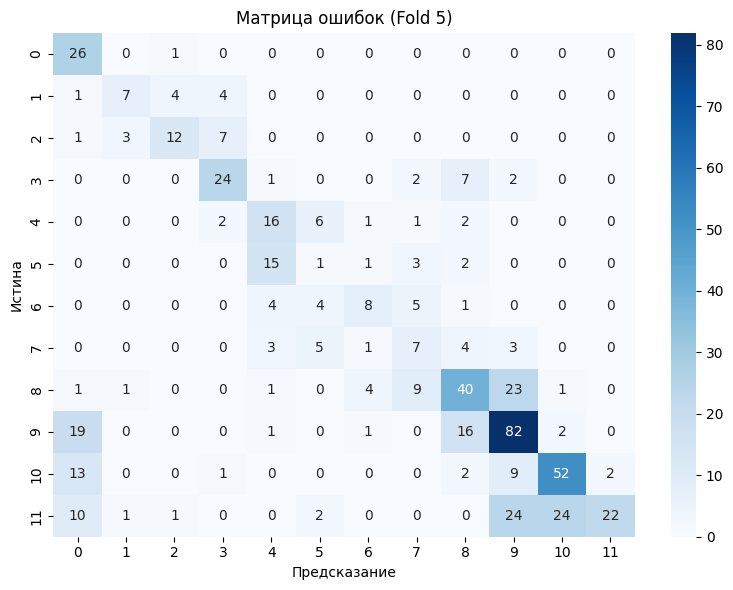

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4894
  Fold 2: F1_macro = 0.5982
  Fold 3: F1_macro = 0.5726
  Fold 4: F1_macro = 0.5516
  Fold 5: F1_macro = 0.4738

  Средний F1 macro: 0.5371 ± 0.0479

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.7872    0.8504    0.8176       448
           1     0.4521    0.4231    0.4371       156
           2     0.5217    0.4615    0.4898       182
           3     0.6088    0.6704    0.6381       267
           4     0.5451    0.6223    0.5812       233
           5     0.3333    0.2105    0.2581       133
           6     0.4492    0.4046    0.4257       131
           7     0.4255    0.3093    0.3582       194
           8     0.4738    0.4959    0.4846       365
           9     0.6259    0.7313    0.6745       469
          10     0.6932    0.6854    0.6893       267
          11     0.7214    0.5519    0.6254       183

    accuracy                         0.5958      

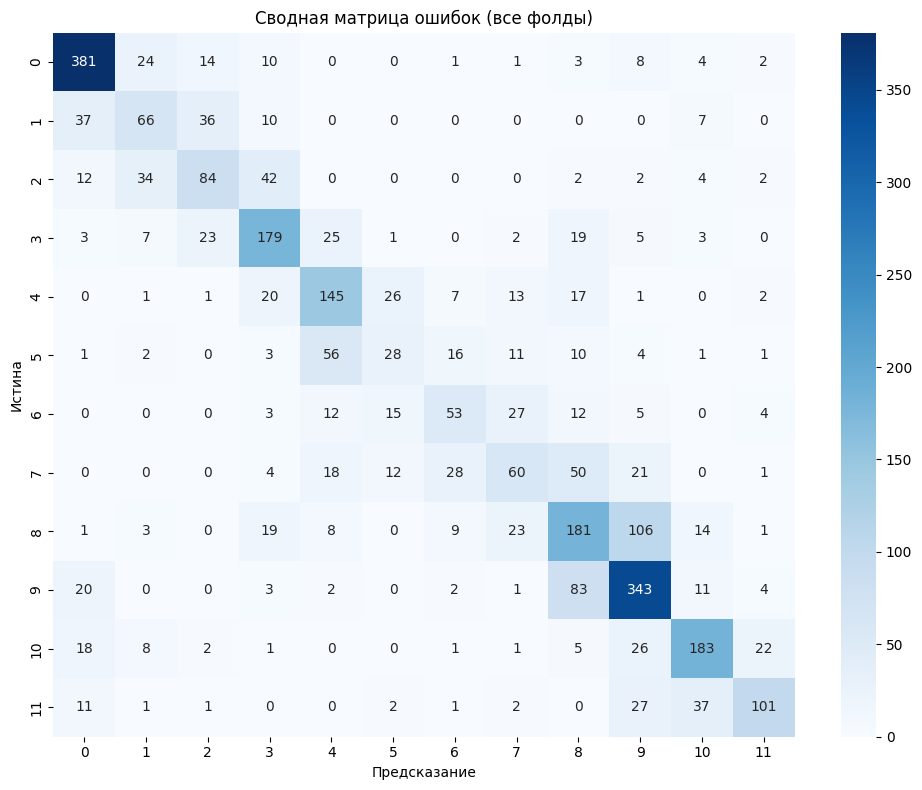

/tmp/ipykernel_329057/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

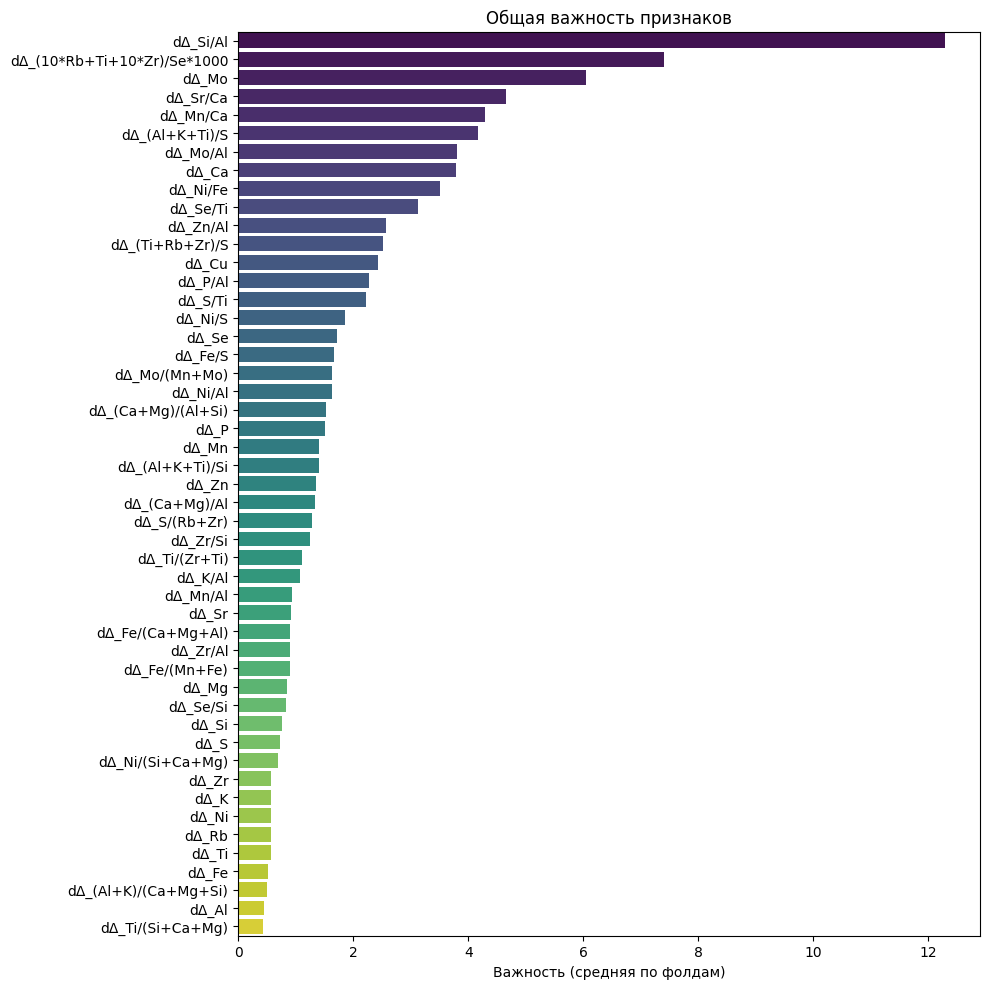

In [57]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Создание относительных градиентов rΔxi = xi / (xi-1 + epsilon)**

In [58]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [59]:
df = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df.groupby('Well')[col].shift(1)
    epsilon = df[col].median() * 0.01
    df[rgrad_col] = df[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df.columns)}")


Добавлено в df: 49 признаков
Всего колонок: 152


In [60]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [14]:
features = ['rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 'rΔ_K', 'rΔ_Ca', 
            'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 
            'rΔ_Rb', 'rΔ_Sr', 'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 
            'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 
            'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 
            'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 
            'rΔ_(Ti+Rb+Zr)/S', 'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 
            'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9974
F1 macro (val):   0.3598
Gap (train-val):  0.6376

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.6897    0.4762    0.5634       126
           1     0.5769    0.2941    0.3896        51
           2     0.2353    0.0870    0.1270        46
           3     0.4839    0.4167    0.4478        72
           4     0.2424    0.3556    0.2883        45
           5     0.1250    0.5000    0.2000         6
           6     0.3333    0.3333    0.3333        21
           7     0.5789    0.1964    0.2933        56
           8     0.2258    0.2857    0.2523        49
           9     0.4400    0.7674    0.5593        86
          10     0.4667    0.4308    0.4480        65
          11     0.3019    0.6667    0.4156        24

    accuracy                    

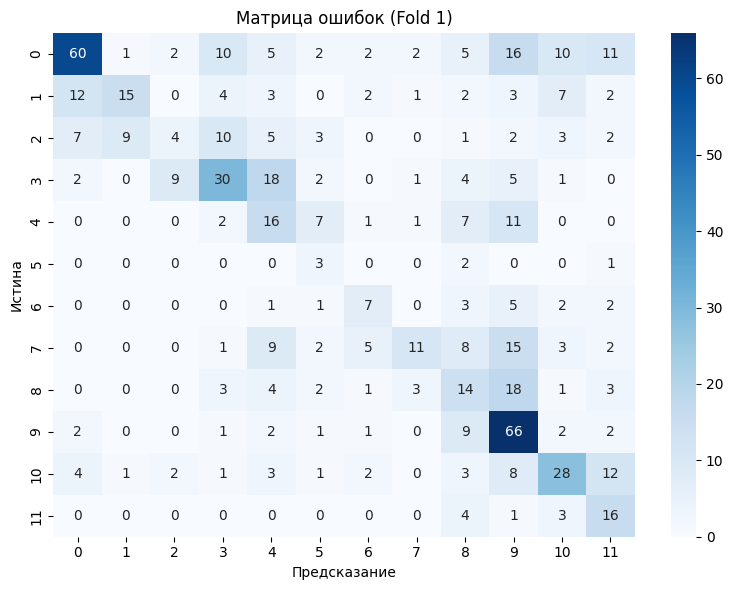

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9963
F1 macro (val):   0.4683
Gap (train-val):  0.5280

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.7838    0.7768    0.7803       112
           1     0.1277    0.4286    0.1967        14
           2     0.5806    0.3913    0.4675        46
           3     0.6825    0.5584    0.6143        77
           4     0.5079    0.4706    0.4885        68
           5     0.4615    0.1333    0.2069        45
           6     0.2500    0.1852    0.2128        27
           7     0.4118    0.4516    0.4308        31
           8     0.4884    0.4941    0.4912        85
           9     0.6220    0.7117    0.6639       111
          10     0.2500    0.4545    0.3226        22
          11     0.6957    0.8000    0.7442        20

    accuracy                    

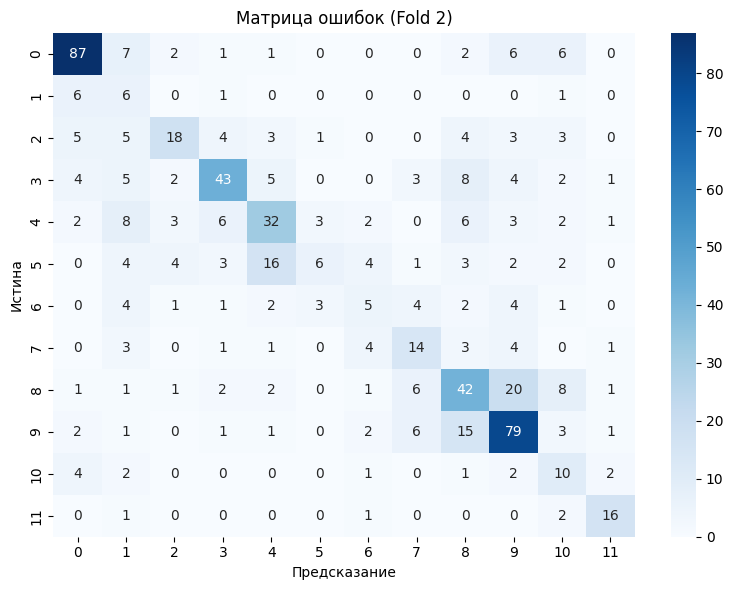

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9949
F1 macro (val):   0.4096
Gap (train-val):  0.5854

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8571    0.8160    0.8361       125
           1     0.5000    0.1944    0.2800        36
           2     0.4783    0.3438    0.4000        32
           3     0.2766    0.4333    0.3377        30
           4     0.4878    0.5556    0.5195        36
           5     0.1429    0.0278    0.0465        36
           6     0.1429    0.0909    0.1111        33
           7     0.3448    0.2500    0.2899        40
           8     0.4151    0.5000    0.4536        88
           9     0.3905    0.5256    0.4481        78
          10     0.5741    0.6889    0.6263        45
          11     0.4545    0.7500    0.5660        20

    accuracy                    

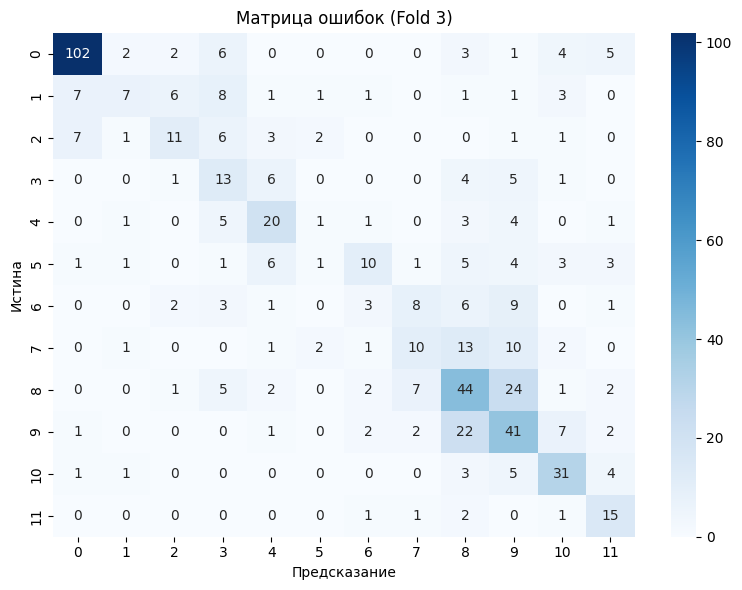

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9958
F1 macro (val):   0.4121
Gap (train-val):  0.5837

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.5714    0.8276    0.6761        58
           1     0.5500    0.2821    0.3729        39
           2     0.4571    0.4571    0.4571        35
           3     0.4792    0.4423    0.4600        52
           4     0.4103    0.2857    0.3368        56
           5     0.1333    0.0833    0.1026        24
           6     0.2581    0.2857    0.2712        28
           7     0.3000    0.1364    0.1875        44
           8     0.2353    0.2540    0.2443        63
           9     0.4690    0.7260    0.5699        73
          10     0.5873    0.6607    0.6218        56
          11     0.7407    0.5714    0.6452        35

    accuracy                    

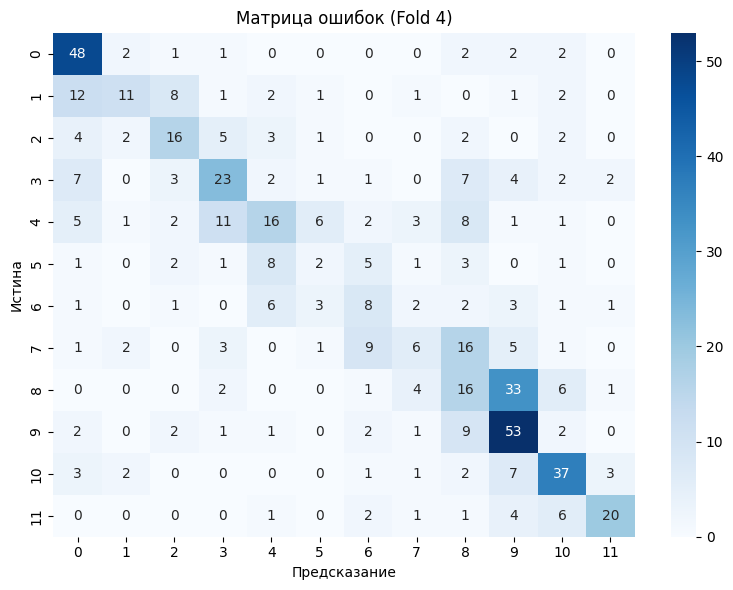

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9943
F1 macro (val):   0.3154
Gap (train-val):  0.6789

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.1797    0.8519    0.2968        27
           1     0.4000    0.2500    0.3077        16
           2     0.4706    0.3478    0.4000        23
           3     0.3824    0.3611    0.3714        36
           4     0.2432    0.3214    0.2769        28
           5     0.1176    0.0909    0.1026        22
           6     0.3684    0.3182    0.3415        22
           7     0.1333    0.0870    0.1053        23
           8     0.4433    0.5375    0.4859        80
           9     0.4677    0.4793    0.4735       121
          10     0.5556    0.3797    0.4511        79
          11     0.8889    0.0952    0.1720        84

    accuracy                    

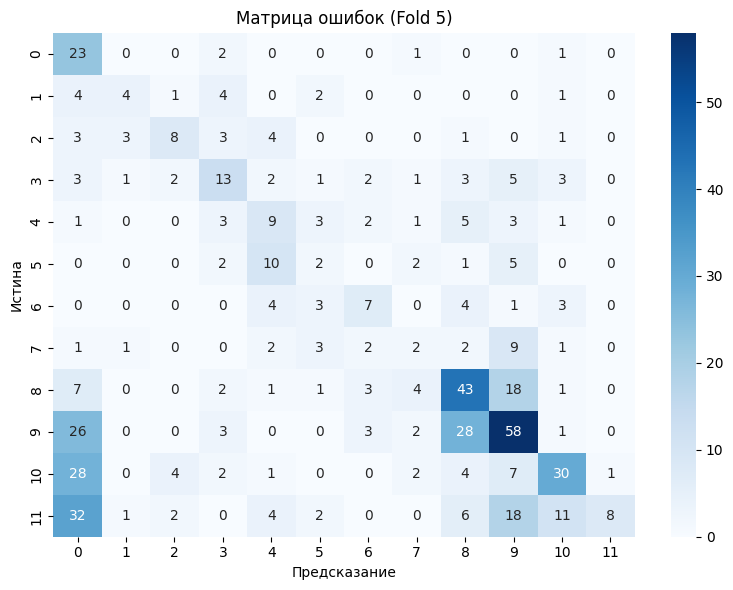

Результаты кросс-валидации
  Fold 1: F1_macro = 0.3598
  Fold 2: F1_macro = 0.4683
  Fold 3: F1_macro = 0.4096
  Fold 4: F1_macro = 0.4121
  Fold 5: F1_macro = 0.3154

  Средний F1 macro: 0.3930 ± 0.0518

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.6049    0.7143    0.6551       448
           1     0.3675    0.2756    0.3150       156
           2     0.4634    0.3132    0.3738       182
           3     0.4803    0.4569    0.4683       267
           4     0.3780    0.3991    0.3883       233
           5     0.1842    0.1053    0.1340       133
           6     0.2679    0.2290    0.2469       131
           7     0.3675    0.2216    0.2765       194
           8     0.3795    0.4356    0.4056       365
           9     0.4798    0.6333    0.5460       469
          10     0.5018    0.5094    0.5056       267
          11     0.5172    0.4098    0.4573       183

    accuracy                         0.4587      

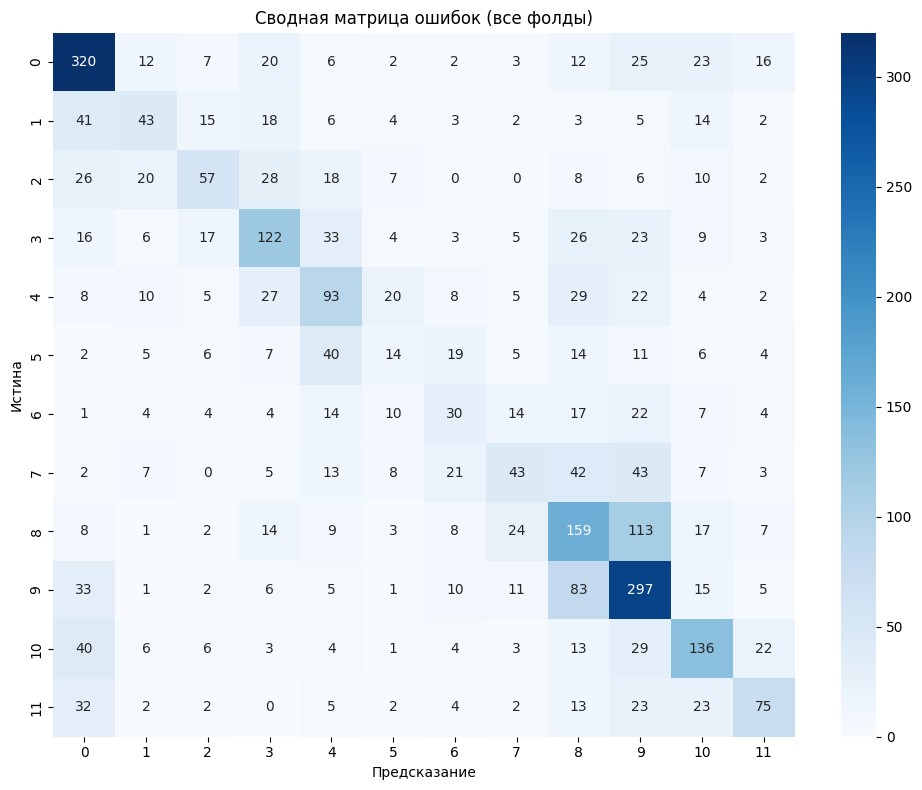

/tmp/ipykernel_329057/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

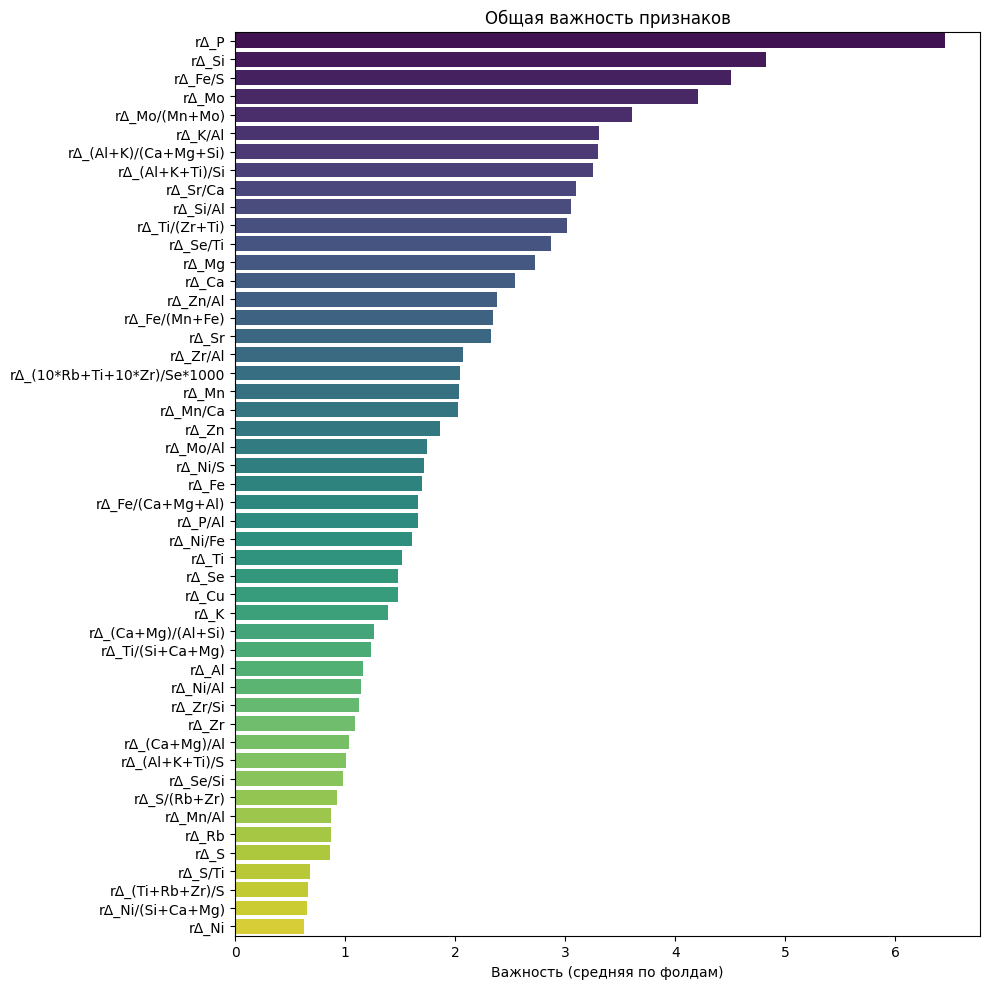

In [15]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**BaseLine. Использование всех признаков**

In [53]:
features = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 
            'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 
            'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'z5_Mg', 'z5_Al', 'z5_Si', 
            'z5_P', 'z5_S', 'z5_K', 'z5_Ca', 'z5_Ti', 'z5_Mn', 'z5_Fe', 'z5_Ni', 'z5_Cu', 'z5_Zn', 
            'z5_Se', 'z5_Rb', 'z5_Sr', 'z5_Zr', 'z5_Mo', 'z5_(Ca+Mg)/(Al+Si)', 'z5_Sr/Ca', 'z5_Mn/Ca', 
            'z5_(Al+K)/(Ca+Mg+Si)', 'z5_Zr/Al', 'z5_Zr/Si', 'z5_K/Al', 'z5_Ti/(Zr+Ti)', 'z5_Si/Al', 
            'z5_P/Al', 'z5_Ni/Fe', 'z5_Ni/(Si+Ca+Mg)', 'z5_S/(Rb+Zr)', 'z5_Mo/Al', 'z5_Mo/(Mn+Mo)', 
            'z5_Mn/Al', 'z5_Fe/S', 'z5_Ni/S', 'z5_Fe/(Ca+Mg+Al)', 'z5_Ti/(Si+Ca+Mg)', 'z5_Fe/(Mn+Fe)', 
            'z5_(Al+K+Ti)/Si', 'z5_(Al+K+Ti)/S', 'z5_(Ti+Rb+Zr)/S', 'z5_S/Ti', 'z5_Ni/Al', 'z5_Zn/Al', 'z5_Se/Si', 
            'z5_(Ca+Mg)/Al', 'z5_Se/Ti', 'z5_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

In [31]:
features = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 
            'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 
            'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

In [25]:
features = ['(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

**Отбор признаков с permutation_importance**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9993
F1 macro (val):   0.5782
Gap (train-val):  0.4211

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9451    0.6825    0.7926       126
           1     0.5968    0.7255    0.6549        51
           2     0.3971    0.5870    0.4737        46
           3     0.5568    0.6806    0.6125        72
           4     0.6111    0.7333    0.6667        45
           5     0.3636    0.6667    0.4706         6
           6     0.3714    0.6190    0.4643        21
           7     0.6316    0.2143    0.3200        56
           8     0.3538    0.4694    0.4035        49
           9     0.7204    0.7791    0.7486        86
          10     0.8636    0.5846    0.6972        65
          11     0.7647    0.5417    0.6341        24

    accuracy                    

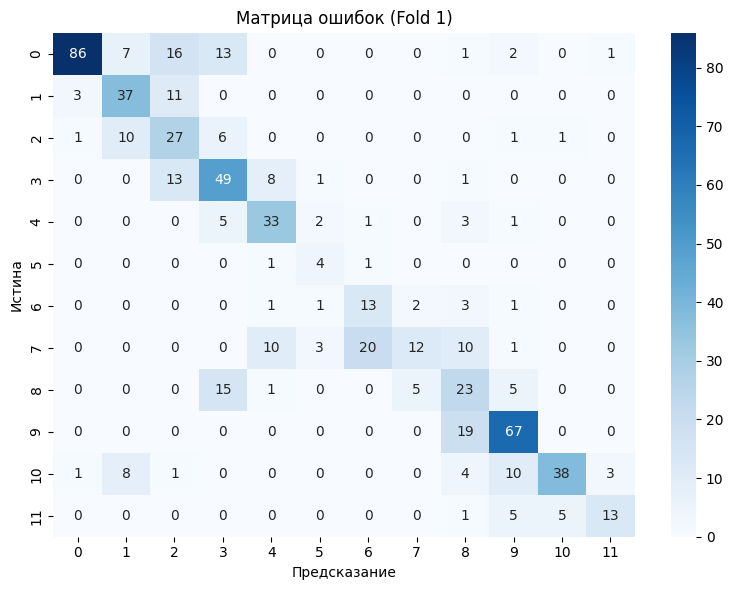

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9986
F1 macro (val):   0.6697
Gap (train-val):  0.3288

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9406    0.8482    0.8920       112
           1     0.3226    0.7143    0.4444        14
           2     0.5217    0.5217    0.5217        46
           3     0.8732    0.8052    0.8378        77
           4     0.6562    0.9265    0.7683        68
           5     0.6000    0.2667    0.3692        45
           6     0.4762    0.3704    0.4167        27
           7     0.4474    0.5484    0.4928        31
           8     0.6562    0.7412    0.6961        85
           9     0.8763    0.7658    0.8173       111
          10     0.9444    0.7727    0.8500        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

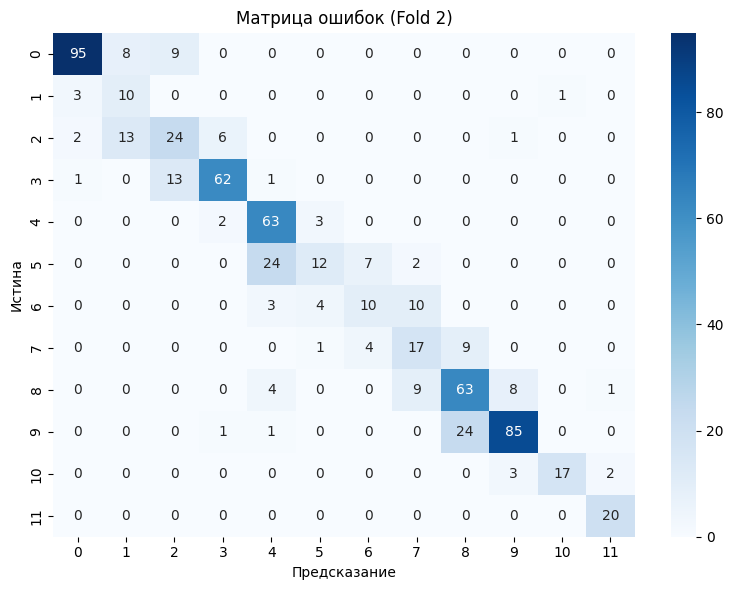

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9987
F1 macro (val):   0.6529
Gap (train-val):  0.3457

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9394    0.9920    0.9650       125
           1     0.8636    0.5278    0.6552        36
           2     0.7000    0.6562    0.6774        32
           3     0.7143    0.8333    0.7692        30
           4     0.6429    0.5000    0.5625        36
           5     0.4400    0.3056    0.3607        36
           6     0.3333    0.1818    0.2353        33
           7     0.3448    0.2500    0.2899        40
           8     0.6134    0.8295    0.7053        88
           9     0.7692    0.8974    0.8284        78
          10     0.8542    0.9111    0.8817        45
          11     0.8636    0.9500    0.9048        20

    accuracy                    

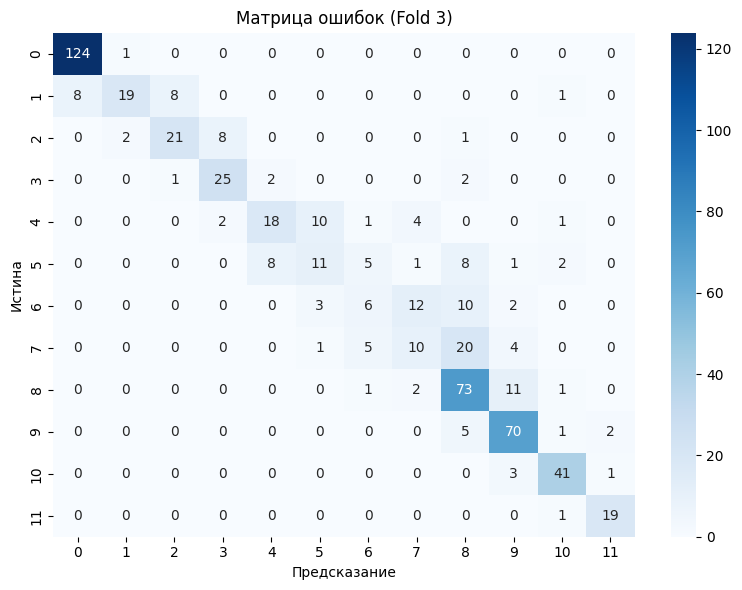

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9979
F1 macro (val):   0.6461
Gap (train-val):  0.3518

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.8923    1.0000    0.9431        58
           1     1.0000    0.4615    0.6316        39
           2     0.4310    0.7143    0.5376        35
           3     0.7292    0.6731    0.7000        52
           4     0.8605    0.6607    0.7475        56
           5     0.5417    0.5417    0.5417        24
           6     0.4412    0.5357    0.4839        28
           7     0.4444    0.1818    0.2581        44
           8     0.4655    0.4286    0.4463        63
           9     0.6471    0.9041    0.7543        73
          10     0.7941    0.9643    0.8710        56
          11     0.9630    0.7429    0.8387        35

    accuracy                    

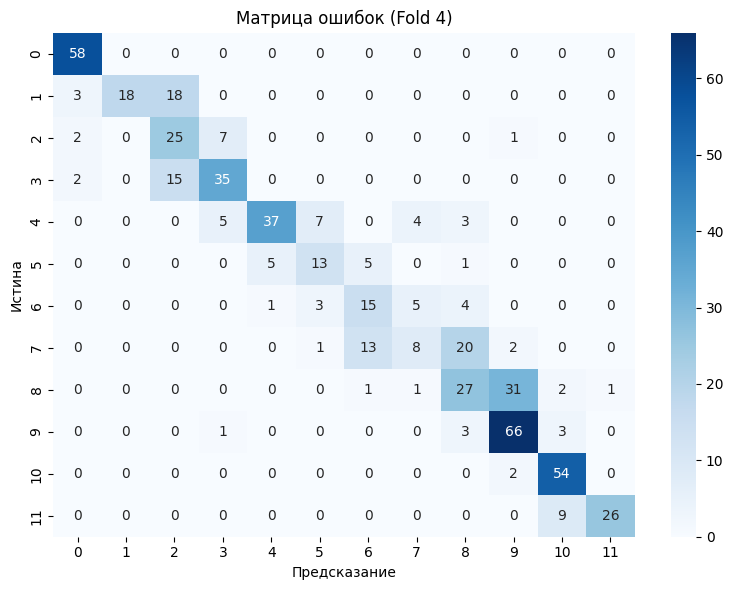

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9984
F1 macro (val):   0.5741
Gap (train-val):  0.4243

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6279    1.0000    0.7714        27
           1     0.7500    0.3750    0.5000        16
           2     0.6154    0.6957    0.6531        23
           3     0.8158    0.8611    0.8378        36
           4     0.4898    0.8571    0.6234        28
           5     0.1667    0.0909    0.1176        22
           6     0.5263    0.4545    0.4878        22
           7     0.2353    0.3478    0.2807        23
           8     0.6029    0.5125    0.5541        80
           9     0.7176    0.7769    0.7460       121
          10     0.6667    0.7848    0.7209        79
          11     0.9250    0.4405    0.5968        84

    accuracy                    

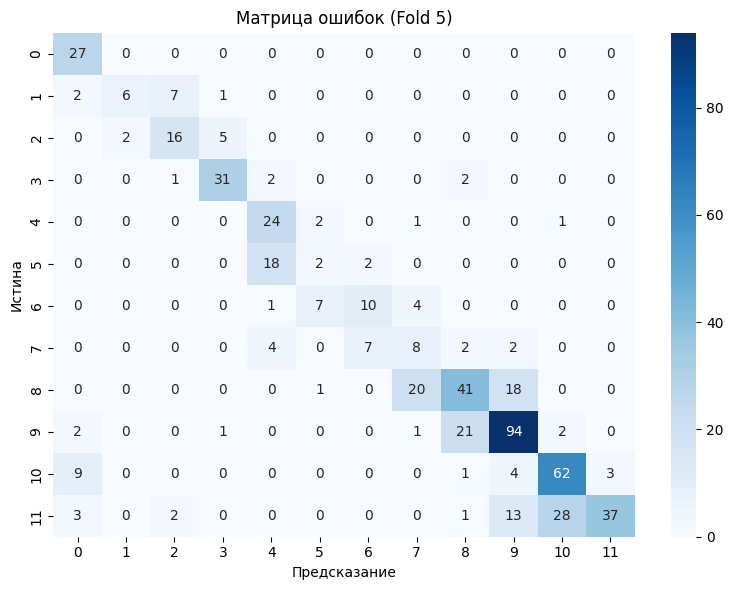

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5782
  Fold 2: F1_macro = 0.6697
  Fold 3: F1_macro = 0.6529
  Fold 4: F1_macro = 0.6461
  Fold 5: F1_macro = 0.5741

  Средний F1 macro: 0.6242 ± 0.0400

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9028    0.8705    0.8864       448
           1     0.6383    0.5769    0.6061       156
           2     0.4956    0.6209    0.5512       182
           3     0.7214    0.7566    0.7386       267
           4     0.6481    0.7511    0.6958       233
           5     0.4565    0.3158    0.3733       133
           6     0.4252    0.4122    0.4186       131
           7     0.3986    0.2835    0.3313       194
           8     0.5591    0.6219    0.5888       365
           9     0.7432    0.8145    0.7772       469
          10     0.7823    0.7940    0.7881       267
          11     0.8915    0.6284    0.7372       183

    accuracy                         0.6793      

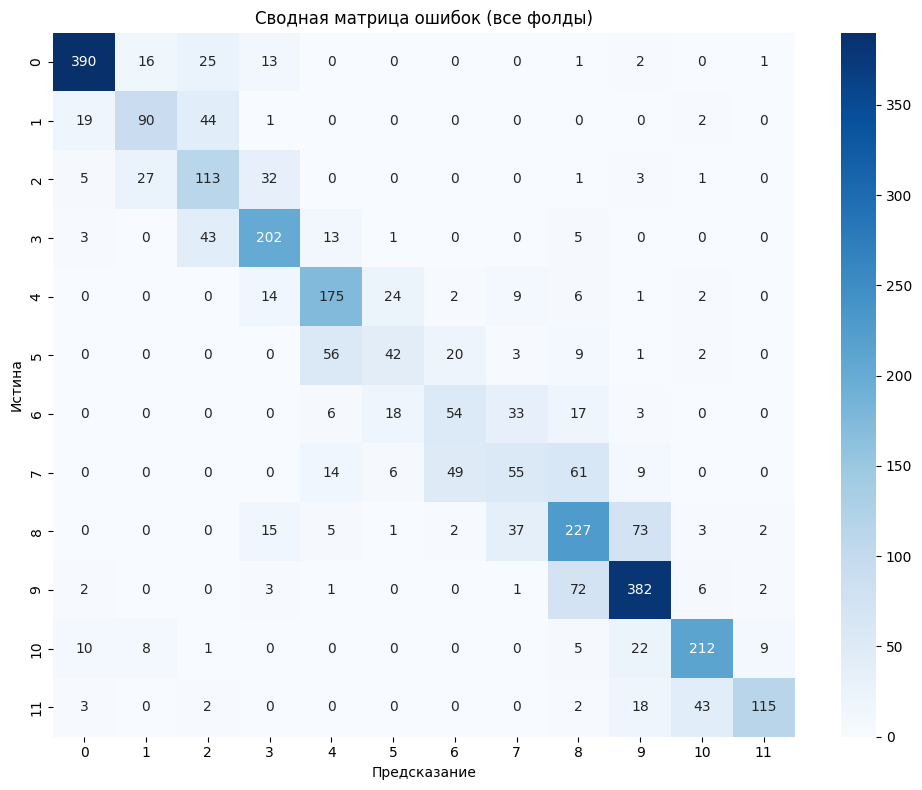

/tmp/ipykernel_329057/678660341.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

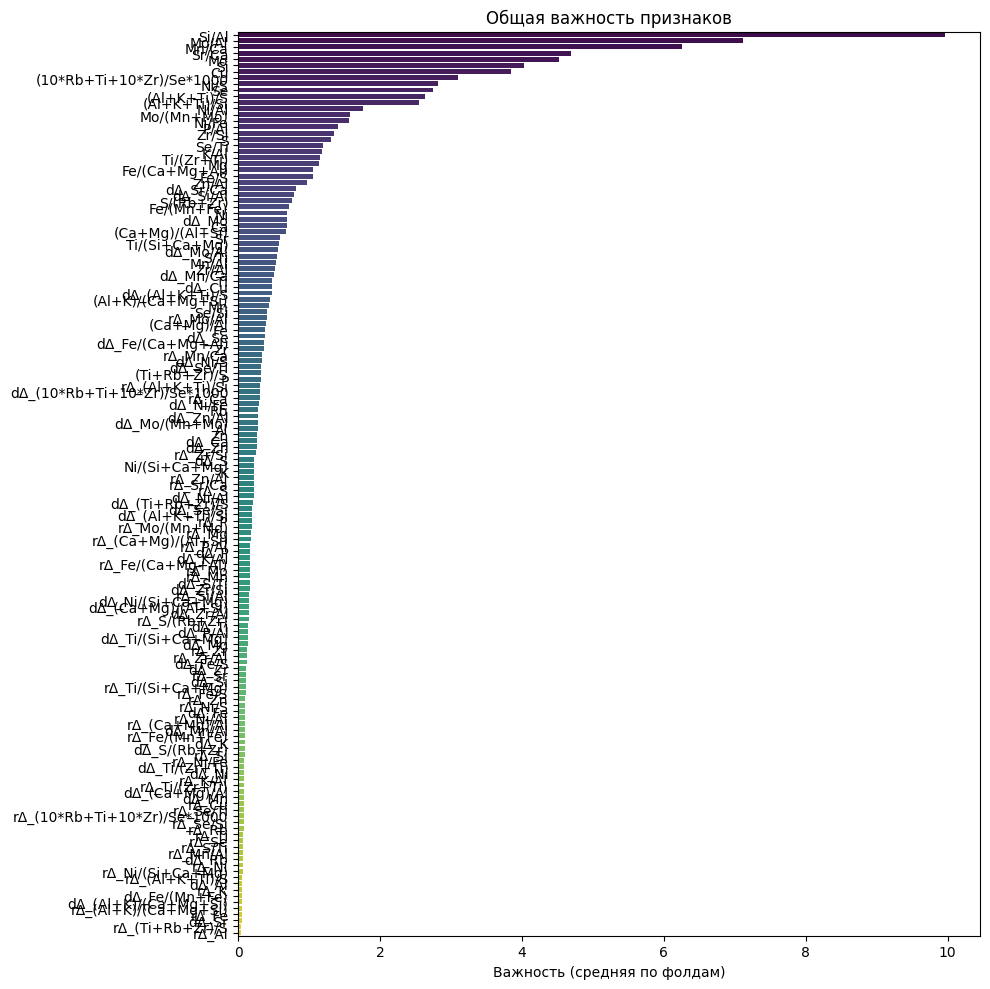


Permutation Importance (агрегировано по 5 фолдам)
Полезных на >=3 фолдах: 123 из 147

Топ-30:
                 feature  n_folds_useful  mean_drop  std_drop
                   Mo/Al               5   0.036631  0.020234
                   Si/Al               5   0.036420  0.017915
                      Cu               5   0.033029  0.013954
                   Sr/Ca               5   0.026726  0.009919
                      Si               5   0.015724  0.004638
              Mo/(Mn+Mo)               5   0.010595  0.005323
             (Al+K+Ti)/S               5   0.009308  0.007298
                    K/Al               5   0.006647  0.005570
                    P/Al               5   0.006067  0.006626
                      Ni               5   0.005244  0.004817
                   Ni/Fe               5   0.004947  0.003410
           Ti/(Si+Ca+Mg)               5   0.004001  0.001994
                   Zr/Al               5   0.003626  0.003375
                 dΔ_K/Al             

/tmp/ipykernel_329057/678660341.py:176: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings

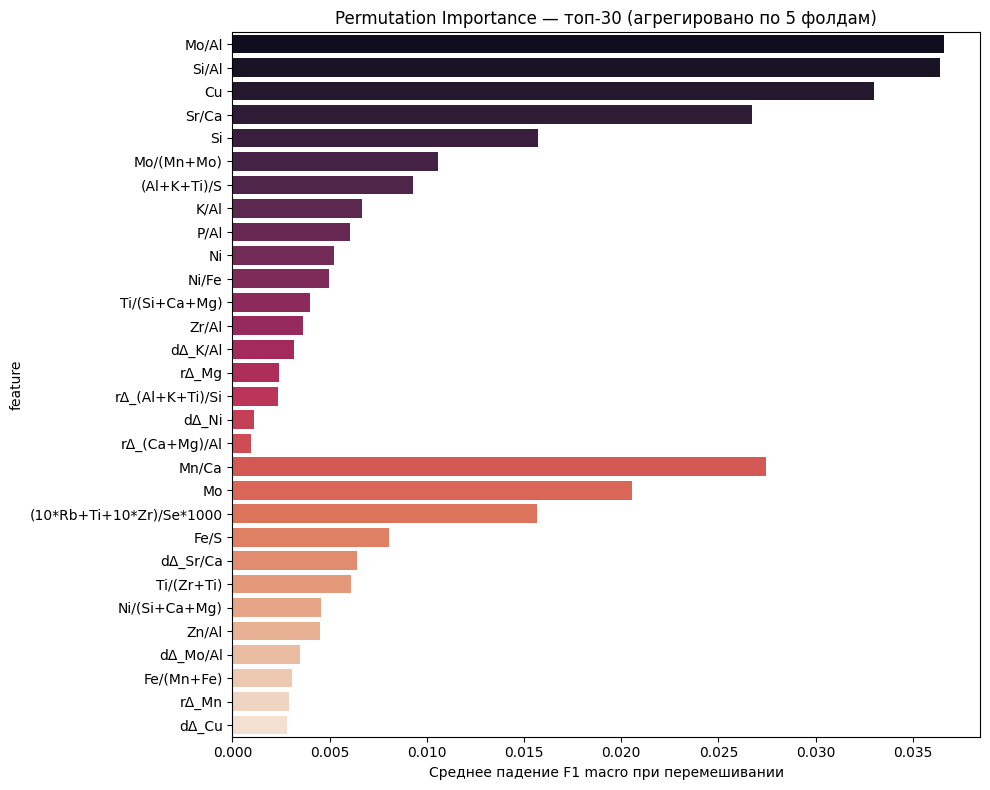


Стабильных признаков: 123
['Mo/Al', 'Si/Al', 'Cu', 'Sr/Ca', 'Si', 'Mo/(Mn+Mo)', '(Al+K+Ti)/S', 'K/Al', 'P/Al', 'Ni', 'Ni/Fe', 'Ti/(Si+Ca+Mg)', 'Zr/Al', 'dΔ_K/Al', 'rΔ_Mg', 'rΔ_(Al+K+Ti)/Si', 'dΔ_Ni', 'rΔ_(Ca+Mg)/Al', 'Mn/Ca', 'Mo', '(10*Rb+Ti+10*Zr)/Se*1000', 'Fe/S', 'dΔ_Sr/Ca', 'Ti/(Zr+Ti)', 'Ni/(Si+Ca+Mg)', 'Zn/Al', 'dΔ_Mo/Al', 'Fe/(Mn+Fe)', 'rΔ_Mn', 'dΔ_Cu', '(Ca+Mg)/(Al+Si)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Si/Al', 'Mg', '(Ti+Rb+Zr)/S', 'Zn', 'dΔ_Zn/Al', 'dΔ_Fe/S', 'dΔ_P/Al', 'Sr', 'dΔ_(Al+K+Ti)/Si', 'rΔ_Zr/Si', 'Zr/Si', 'rΔ_S', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mn/Ca', 'rΔ_Mo', 'rΔ_Mo/Al', 'rΔ_Zn/Al', 'dΔ_Se/Si', 'dΔ_Al', 'dΔ_Ni/Al', 'rΔ_Cu', 'rΔ_Rb', 'rΔ_Se/Si', 'rΔ_Ti/(Zr+Ti)', 'rΔ_S/(Rb+Zr)', 'dΔ_Fe/(Ca+Mg+Al)', '(Al+K+Ti)/Si', 'rΔ_P/Al', 'dΔ_S/(Rb+Zr)', 'Se', 'dΔ_Mo', 'Fe', 'Ni/Al', 'Se/Si', 'S', 'rΔ_Ca', 'dΔ_Se', 'dΔ_Zn', 'dΔ_Si', '(Ca+Mg)/Al', 'Ca', 'rΔ_Ni/Fe', 'Mn/Al', 'rΔ_Zr/Al', 'rΔ_Si/Al', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_P', 'Rb', 'dΔ_Mn/Al', 'dΔ_S/Ti', 'dΔ_(Ti+Rb+Zr)/S', '

In [34]:
from sklearn.metrics import f1_score
import numpy as np

X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []
importance_all = []

# Накопитель для permutation importance
perm_all = []  # список dict: {feature: drop_f1} для каждого фолда

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    shap_per_class = shap_values[:, :, :-1]
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Permutation importance для текущего фолда
    rng = np.random.RandomState(42)
    perm_results = {}
    for i, col in enumerate(X_vl.columns):
        scores = []
        for _ in range(3):
            X_perm = X_vl.copy()
            X_perm.iloc[:, i] = rng.permutation(X_perm.iloc[:, i].values)
            scores.append(f1_score(y_vl, model.predict(X_perm), average='macro'))
        perm_results[col] = f1_val - np.mean(scores)
    perm_all.append(perm_results)
    print(f"  Permutation importance посчитан для {len(perm_results)} признаков")

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")

print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

# ── Permutation Importance: агрегация по фолдам ──
n_folds = len(perm_all)
min_folds_useful = n_folds // 2 + 1  # больше половины фолдов

perm_summary = pd.DataFrame({
    'feature': features,
    'n_folds_useful': [sum(1 for res in perm_all if res[col] > 0) for col in features],
    'mean_drop': [np.mean([res[col] for res in perm_all]) for col in features],
    'std_drop': [np.std([res[col] for res in perm_all]) for col in features]
}).sort_values(['n_folds_useful', 'mean_drop'], ascending=[False, False])

print(f"\nPermutation Importance (агрегировано по {n_folds} фолдам)")
print(f"Полезных на >={min_folds_useful} фолдах: "
      f"{(perm_summary['n_folds_useful'] >= min_folds_useful).sum()} из {len(features)}")
print(f"\nТоп-30:")
print(perm_summary.head(30).to_string(index=False))

print(f"\nБесполезные на всех фолдах (n_folds_useful=0): "
      f"{(perm_summary['n_folds_useful'] == 0).sum()}")

# Топ-30 permutation importance
plt.figure(figsize=(10, 8))
top30 = perm_summary.head(30)
sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
plt.xlabel('Среднее падение F1 macro при перемешивании')
plt.title(f'Permutation Importance — топ-30 (агрегировано по {n_folds} фолдам)')
plt.tight_layout()
plt.show()

# Список стабильных признаков
stable_features = perm_summary[perm_summary['n_folds_useful'] >= min_folds_useful]['feature'].tolist()
print(f"\nСтабильных признаков: {len(stable_features)}")
print(stable_features)


**Жесткий отбор признаков n_folds_useful >= 4**

Признаков до отбора: 147
Признаков после жёсткого отбора (>= 4 фолдов): 61
Fold 1
  Train: 2381 проб, Val: 647 проб
  F1 macro (train): 0.9986
  F1 macro (val):   0.5771
  Gap:              0.4215
Fold 2
  Train: 2370 проб, Val: 658 проб
  F1 macro (train): 0.9983
  F1 macro (val):   0.6824
  Gap:              0.3159
Fold 3
  Train: 2429 проб, Val: 599 проб
  F1 macro (train): 0.9992
  F1 macro (val):   0.6728
  Gap:              0.3264
Fold 4
  Train: 2465 проб, Val: 563 проб
  F1 macro (train): 0.9983
  F1 macro (val):   0.6587
  Gap:              0.3396
Fold 5
  Train: 2467 проб, Val: 561 проб
  F1 macro (train): 0.9983
  F1 macro (val):   0.5859
  Gap:              0.4124

Результаты жёсткого отбора (>= 4 фолдов, 61 признаков)
  Средний F1 macro: 0.6354 ± 0.0447

Сводный Classification Report:
              precision    recall  f1-score   support

           0     0.9128    0.8884    0.9005       448
           1     0.6642    0.5705    0.6138       156
           2     0.4936    0

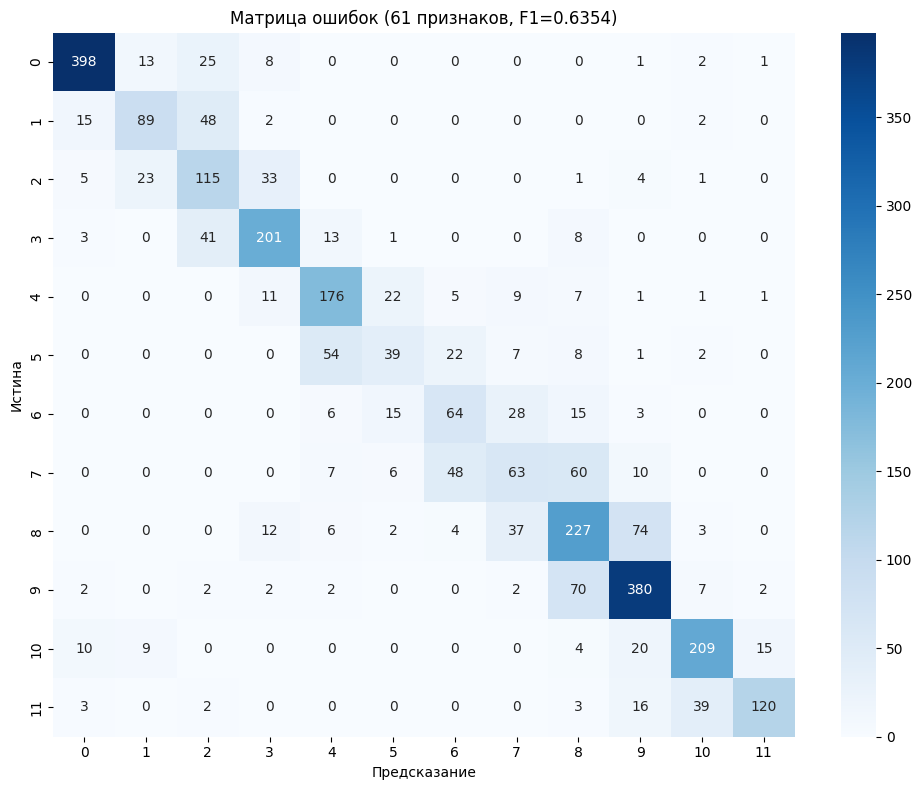

In [35]:
# Жёсткий отбор: только n_folds_useful >= 4
strict_features = perm_summary[perm_summary['n_folds_useful'] >= 4]['feature'].tolist()

print(f"Признаков до отбора: {len(features)}")
print(f"Признаков после жёсткого отбора (>= 4 фолдов): {len(strict_features)}")

# Перезапускаем кросс-валидацию на отобранных признаках
X = df[strict_features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_strict = []
all_preds_strict = []
all_true_strict = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]

    print(f"Fold {fold}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores_strict.append(f1_val)
    all_preds_strict.extend(y_pred)
    all_true_strict.extend(y_vl.values)

    print(f"  F1 macro (train): {f1_train:.4f}")
    print(f"  F1 macro (val):   {f1_val:.4f}")
    print(f"  Gap:              {gap:.4f}")

print(f"\n{'='*50}")
print(f"Результаты жёсткого отбора (>= 4 фолдов, {len(strict_features)} признаков)")
print(f"  Средний F1 macro: {np.mean(fold_scores_strict):.4f} ± {np.std(fold_scores_strict):.4f}")
print(f"\nСводный Classification Report:")
print(classification_report(all_true_strict, all_preds_strict, digits=4))

plt.figure(figsize=(10, 8))
cm_strict = confusion_matrix(all_true_strict, all_preds_strict)
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок ({len(strict_features)} признаков, F1={np.mean(fold_scores_strict):.4f})')
plt.tight_layout()
plt.show()


**Viterbi-постобработка**

In [36]:
from collections import Counter

X = df[strict_features]
y = df['Strat']
groups = df['Well']

# 1. Оценка transition matrix по тренировочным данным
def build_transition_matrix(y_train, wells_train, n_classes=12):
    """Считаем переходы между классами по глубине внутри каждой скважины"""
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    # Нормализуем строки
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

# 2. Оценка начальных распределений
def build_start_probs(y_train, wells_train, n_classes=12):
    """Какой класс чаще всего встречается первым в скважине"""
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

# 3. Viterbi-декодирование для одной скважины
def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    probs_well: (n_samples, n_classes) — вероятности от CatBoost
    Возвращает наиболее правдоподобную последовательность классов
    """
    n_samples, n_classes = probs_well.shape
    
    # Логарифмируем для численной устойчивости
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    # Viterbi: dp[t, j] = max вероятность пути, заканчивающегося в классе j на шаге t
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    # Инициализация
    dp[0] = log_start + log_emission[0]
    
    # Рекурсия
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    # Backtrack
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path

# 4. Полный пайплайн с Viterbi
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []
all_preds_raw = []
all_preds_viterbi = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    wells_tr, wells_vl = groups.iloc[train_idx], groups.iloc[val_idx]
    
    # Обучаем CatBoost
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # Сырые предсказания
    y_pred_raw = model.predict(X_vl).ravel()
    
    # Вероятности для Viterbi
    probs = model.predict_proba(X_vl)
    
    # Строим HMM по тренировочным данным
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Viterbi для каждой скважины отдельно
    y_pred_viterbi = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        well_mask = (wells_vl == well).values
        if well_mask.sum() == 0:
            continue
        probs_well = probs[well_mask]
        path = viterbi_decode(probs_well, trans_mat, start_probs)
        y_pred_viterbi[well_mask] = path
    
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    f1_vit = f1_score(y_vl, y_pred_viterbi, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    all_preds_raw.extend(y_pred_raw)
    all_preds_viterbi.extend(y_pred_viterbi)
    all_true.extend(y_vl.values)
    
    print(f"Fold {fold}: F1 raw={f1_raw:.4f} → F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")

print(f"\n{'='*50}")
print(f"Средний F1 raw:    {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

print(f"\nClassification Report (Viterbi):")
print(classification_report(all_true, all_preds_viterbi, digits=4))


Fold 1: F1 raw=0.5771 → F1 Viterbi=0.7412 (+16.4%)
Fold 2: F1 raw=0.6824 → F1 Viterbi=0.7524 (+7.0%)
Fold 3: F1 raw=0.6728 → F1 Viterbi=0.7556 (+8.3%)
Fold 4: F1 raw=0.6587 → F1 Viterbi=0.7382 (+7.9%)
Fold 5: F1 raw=0.5859 → F1 Viterbi=0.6490 (+6.3%)

Средний F1 raw:    0.6354 ± 0.0447
Средний F1 Viterbi: 0.7273 ± 0.0397

Classification Report (Viterbi):
              precision    recall  f1-score   support

           0     0.9774    0.9665    0.9719       448
           1     0.8689    0.6795    0.7626       156
           2     0.6364    0.7308    0.6803       182
           3     0.8525    0.8876    0.8697       267
           4     0.7407    0.9442    0.8302       233
           5     0.6226    0.2481    0.3548       133
           6     0.5149    0.5267    0.5208       131
           7     0.5646    0.4278    0.4868       194
           8     0.6802    0.7808    0.7270       365
           9     0.8314    0.9041    0.8662       469
          10     0.8328    0.8951    0.8628     

In [1]:
import os
print(os.getcwd())

/home/maria/ML_for_geochemistry


**Список отобранных признаков**

In [37]:
strict_features

['Mo/Al',
 'Si/Al',
 'Cu',
 'Sr/Ca',
 'Si',
 'Mo/(Mn+Mo)',
 '(Al+K+Ti)/S',
 'K/Al',
 'P/Al',
 'Ni',
 'Ni/Fe',
 'Ti/(Si+Ca+Mg)',
 'Zr/Al',
 'dΔ_K/Al',
 'rΔ_Mg',
 'rΔ_(Al+K+Ti)/Si',
 'dΔ_Ni',
 'rΔ_(Ca+Mg)/Al',
 'Mn/Ca',
 'Mo',
 '(10*Rb+Ti+10*Zr)/Se*1000',
 'Fe/S',
 'dΔ_Sr/Ca',
 'Ti/(Zr+Ti)',
 'Ni/(Si+Ca+Mg)',
 'Zn/Al',
 'dΔ_Mo/Al',
 'Fe/(Mn+Fe)',
 'rΔ_Mn',
 'dΔ_Cu',
 '(Ca+Mg)/(Al+Si)',
 'dΔ_Ni/(Si+Ca+Mg)',
 'dΔ_Si/Al',
 'Mg',
 '(Ti+Rb+Zr)/S',
 'Zn',
 'dΔ_Zn/Al',
 'dΔ_Fe/S',
 'dΔ_P/Al',
 'Sr',
 'dΔ_(Al+K+Ti)/Si',
 'rΔ_Zr/Si',
 'Zr/Si',
 'rΔ_S',
 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000',
 'rΔ_Mn/Ca',
 'rΔ_Mo',
 'rΔ_Mo/Al',
 'rΔ_Zn/Al',
 'dΔ_Se/Si',
 'dΔ_Al',
 'dΔ_Ni/Al',
 'rΔ_Cu',
 'rΔ_Rb',
 'rΔ_Se/Si',
 'rΔ_Ti/(Zr+Ti)',
 'rΔ_S/(Rb+Zr)',
 'dΔ_Fe/(Ca+Mg+Al)',
 '(Al+K+Ti)/Si',
 'rΔ_P/Al',
 'dΔ_S/(Rb+Zr)']

**Попали 6 элементов**

**Эксперименты со шламом. Применение baseline + Viterbi к синтетическому шламу**

In [47]:
# Проверить, какие колонки есть в df
print(df.columns.tolist())

# Проверить, каких не хватает
missing_kern = [f for f in strict_features if f not in df.columns]
print("Отсутствуют в керне:", missing_kern)

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000']
Отсутствуют в керне: ['dΔ_K/Al', 'rΔ_Mg', 'rΔ_(Al+K+Ti)/Si', 'dΔ_Ni', 'rΔ_(Ca+Mg)/Al', 'dΔ_Sr/Ca', 'dΔ_Mo/Al', 'rΔ_Mn', 'dΔ_Cu', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Si/Al', 'dΔ_Zn/Al', 'dΔ_Fe/S', 'dΔ_P/Al', 'dΔ_(Al+K+Ti)/Si', 'rΔ_Zr/Si', 'rΔ_S', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mn/Ca', 'rΔ_Mo', 'rΔ_Mo/Al', 'rΔ_Zn/Al', 'dΔ_Se/Si', 'dΔ_Al', 'dΔ_Ni/Al', 'rΔ_Cu', 'rΔ_Rb', 'rΔ_Se/Si', 'rΔ_Ti/(Zr+Ti)', 'rΔ_S/(Rb+Zr)', 'dΔ_Fe/(Ca+Mg+Al)', 'rΔ_P/Al', 'dΔ_S/(Rb+Zr)']


In [62]:
import warnings
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

In [63]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score
import os

# ═══════════════════════════════════════════════════════════════
# 1. ДАННЫЕ
# ═══════════════════════════════════════════════════════════════
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

strict_features = [
    'Mo/Al', 'Si/Al', 'Cu', 'Sr/Ca', 'Si', 'Mo/(Mn+Mo)', '(Al+K+Ti)/S',
    'K/Al', 'P/Al', 'Ni', 'Ni/Fe', 'Ti/(Si+Ca+Mg)', 'Zr/Al',
    'dΔ_K/Al', 'rΔ_Mg', 'rΔ_(Al+K+Ti)/Si', 'dΔ_Ni', 'rΔ_(Ca+Mg)/Al',
    'Mn/Ca', 'Mo', '(10*Rb+Ti+10*Zr)/Se*1000', 'Fe/S', 'dΔ_Sr/Ca',
    'Ti/(Zr+Ti)', 'Ni/(Si+Ca+Mg)', 'Zn/Al', 'dΔ_Mo/Al', 'Fe/(Mn+Fe)',
    'rΔ_Mn', 'dΔ_Cu', '(Ca+Mg)/(Al+Si)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Si/Al',
    'Mg', '(Ti+Rb+Zr)/S', 'Zn', 'dΔ_Zn/Al', 'dΔ_Fe/S', 'dΔ_P/Al',
    'Sr', 'dΔ_(Al+K+Ti)/Si', 'rΔ_Zr/Si', 'Zr/Si', 'rΔ_S',
    'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mn/Ca', 'rΔ_Mo', 'rΔ_Mo/Al',
    'rΔ_Zn/Al', 'dΔ_Se/Si', 'dΔ_Al', 'dΔ_Ni/Al', 'rΔ_Cu', 'rΔ_Rb',
    'rΔ_Se/Si', 'rΔ_Ti/(Zr+Ti)', 'rΔ_S/(Rb+Zr)', 'dΔ_Fe/(Ca+Mg+Al)',
    '(Al+K+Ti)/Si', 'rΔ_P/Al', 'dΔ_S/(Rb+Zr)'
]

X_kern = df[strict_features]
y_kern = df['Strat']
groups_kern = df['Well']

# ═══════════════════════════════════════════════════════════════
# 2. ФУНКЦИЯ: ВСЕ ПРИЗНАКИ ДЛЯ ШЛАМА
# ═══════════════════════════════════════════════════════════════

def compute_all_features(df, elements, suffix):
    """Считает все соотношения + dΔ_ + rΔ_ для всех признаков."""
    df = df.sort_values(['Well', 'Depth']).reset_index(drop=True)
    eps = 1e-10
    
    # ── ВСЕ СООТНОШЕНИЯ ──
    df[f'(Ca+Mg)/(Al+Si){suffix}'] = (df[f'Ca{suffix}'] + df[f'Mg{suffix}']) / (df[f'Al{suffix}'] + df[f'Si{suffix}'] + eps)
    df[f'Sr/Ca{suffix}'] = df[f'Sr{suffix}'] / (df[f'Ca{suffix}'] + eps)
    df[f'Mn/Ca{suffix}'] = df[f'Mn{suffix}'] / (df[f'Ca{suffix}'] + eps)
    df[f'(Al+K)/(Ca+Mg+Si){suffix}'] = (df[f'Al{suffix}'] + df[f'K{suffix}']) / (df[f'Ca{suffix}'] + df[f'Mg{suffix}'] + df[f'Si{suffix}'] + eps)
    df[f'Zr/Al{suffix}'] = df[f'Zr{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Zr/Si{suffix}'] = df[f'Zr{suffix}'] / (df[f'Si{suffix}'] + eps)
    df[f'K/Al{suffix}'] = df[f'K{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Ti/(Zr+Ti){suffix}'] = df[f'Ti{suffix}'] / (df[f'Zr{suffix}'] + df[f'Ti{suffix}'] + eps)
    df[f'Si/Al{suffix}'] = df[f'Si{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'P/Al{suffix}'] = df[f'P{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Ni/Fe{suffix}'] = df[f'Ni{suffix}'] / (df[f'Fe{suffix}'] + eps)
    df[f'Ni/(Si+Ca+Mg){suffix}'] = df[f'Ni{suffix}'] / (df[f'Si{suffix}'] + df[f'Ca{suffix}'] + df[f'Mg{suffix}'] + eps)
    df[f'S/(Rb+Zr){suffix}'] = df[f'S{suffix}'] / (df[f'Rb{suffix}'] + df[f'Zr{suffix}'] + eps)
    df[f'Mo/Al{suffix}'] = df[f'Mo{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Mo/(Mn+Mo){suffix}'] = df[f'Mo{suffix}'] / (df[f'Mn{suffix}'] + df[f'Mo{suffix}'] + eps)
    df[f'Mn/Al{suffix}'] = df[f'Mn{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Fe/S{suffix}'] = df[f'Fe{suffix}'] / (df[f'S{suffix}'] + eps)
    df[f'Ni/S{suffix}'] = df[f'Ni{suffix}'] / (df[f'S{suffix}'] + eps)
    df[f'Fe/(Ca+Mg+Al){suffix}'] = df[f'Fe{suffix}'] / (df[f'Ca{suffix}'] + df[f'Mg{suffix}'] + df[f'Al{suffix}'] + eps)
    df[f'Ti/(Si+Ca+Mg){suffix}'] = df[f'Ti{suffix}'] / (df[f'Si{suffix}'] + df[f'Ca{suffix}'] + df[f'Mg{suffix}'] + eps)
    df[f'Fe/(Mn+Fe){suffix}'] = df[f'Fe{suffix}'] / (df[f'Mn{suffix}'] + df[f'Fe{suffix}'] + eps)
    df[f'(Al+K+Ti)/Si{suffix}'] = (df[f'Al{suffix}'] + df[f'K{suffix}'] + df[f'Ti{suffix}']) / (df[f'Si{suffix}'] + eps)
    df[f'(Al+K+Ti)/S{suffix}'] = (df[f'Al{suffix}'] + df[f'K{suffix}'] + df[f'Ti{suffix}']) / (df[f'S{suffix}'] + eps)
    df[f'(Ti+Rb+Zr)/S{suffix}'] = (df[f'Ti{suffix}'] + df[f'Rb{suffix}'] + df[f'Zr{suffix}']) / (df[f'S{suffix}'] + eps)
    df[f'S/Ti{suffix}'] = df[f'S{suffix}'] / (df[f'Ti{suffix}'] + eps)
    df[f'Ni/Al{suffix}'] = df[f'Ni{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Zn/Al{suffix}'] = df[f'Zn{suffix}'] / (df[f'Al{suffix}'] + eps)
    df[f'Se/Si{suffix}'] = df[f'Se{suffix}'] / (df[f'Si{suffix}'] + eps)
    df[f'(Ca+Mg)/Al{suffix}'] = (df[f'Ca{suffix}'] + df[f'Mg{suffix}']) / (df[f'Al{suffix}'] + eps)
    df[f'Se/Ti{suffix}'] = df[f'Se{suffix}'] / (df[f'Ti{suffix}'] + eps)
    df[f'(10*Rb+Ti+10*Zr)/Se*1000{suffix}'] = (10*df[f'Rb{suffix}'] + df[f'Ti{suffix}'] + 10*df[f'Zr{suffix}']) / (df[f'Se{suffix}'] + eps) * 1000
    
    # ── СПИСОК ВСЕХ ПРИЗНАКОВ ──
    all_base = [f'{el}{suffix}' for el in elements] + [
        f'(Ca+Mg)/(Al+Si){suffix}', f'Sr/Ca{suffix}', f'Mn/Ca{suffix}',
        f'(Al+K)/(Ca+Mg+Si){suffix}', f'Zr/Al{suffix}', f'Zr/Si{suffix}',
        f'K/Al{suffix}', f'Ti/(Zr+Ti){suffix}', f'Si/Al{suffix}', f'P/Al{suffix}',
        f'Ni/Fe{suffix}', f'Ni/(Si+Ca+Mg){suffix}', f'S/(Rb+Zr){suffix}',
        f'Mo/Al{suffix}', f'Mo/(Mn+Mo){suffix}', f'Mn/Al{suffix}',
        f'Fe/S{suffix}', f'Ni/S{suffix}', f'Fe/(Ca+Mg+Al){suffix}',
        f'Ti/(Si+Ca+Mg){suffix}', f'Fe/(Mn+Fe){suffix}', f'(Al+K+Ti)/Si{suffix}',
        f'(Al+K+Ti)/S{suffix}', f'(Ti+Rb+Zr)/S{suffix}', f'S/Ti{suffix}',
        f'Ni/Al{suffix}', f'Zn/Al{suffix}', f'Se/Si{suffix}',
        f'(Ca+Mg)/Al{suffix}', f'Se/Ti{suffix}', f'(10*Rb+Ti+10*Zr)/Se*1000{suffix}'
    ]
    
    # ── dΔ_ ──
    for col in all_base:
        if col not in df.columns:
            continue
        df[f'dΔ_{col}'] = df.groupby('Well')[col].diff()
    
    # ── rΔ_ ──
    for col in all_base:
        if col not in df.columns:
            continue
        prev = df.groupby('Well')[col].shift(1)
        epsilon = df[col].median() * 0.01
        df[f'rΔ_{col}'] = df[col] / (prev + epsilon)
    
    return df

# ═══════════════════════════════════════════════════════════════
# 3. VITERBI
# ═══════════════════════════════════════════════════════════════

def build_transition_matrix(y_train, wells_train, n_classes=12):
    trans = np.ones((n_classes, n_classes))
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    return trans / trans.sum(axis=1, keepdims=True)

def build_start_probs(y_train, wells_train, n_classes=12):
    start = np.ones(n_classes)
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

def viterbi_decode(probs_well, trans_mat, start_probs):
    n_samples, n_classes = probs_well.shape
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    return path

# ═══════════════════════════════════════════════════════════════
# 4. ПАРАМЕТРЫ
# ═══════════════════════════════════════════════════════════════

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1, 'l2_leaf_reg': 3,
    'loss_function': 'MultiClass', 'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

windows = [0.5, 1.0, 2.0, 3.0]
noise_levels = [0, 0.1, 0.3, 0.5]

os.makedirs('Result/models', exist_ok=True)

# ═══════════════════════════════════════════════════════════════
# 5. CV НА КЕРНЕ + ПРИМЕНЕНИЕ К ШЛАМУ
# ═══════════════════════════════════════════════════════════════

gkf = GroupKFold(n_splits=5)
results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_kern, y_kern, groups_kern), 1):
    print(f"\n{'='*60}")
    print(f"Fold {fold}")
    
    X_tr = X_kern.iloc[train_idx]
    y_tr = y_kern.iloc[train_idx]
    X_vl_kern = X_kern.iloc[val_idx]
    y_vl_kern = y_kern.iloc[val_idx]
    wells_tr = groups_kern.iloc[train_idx]
    wells_vl = groups_kern.iloc[val_idx]
    val_wells = wells_vl.unique()
    
    print(f"  Val wells: {sorted(val_wells)}")
    
    # Обучение
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    model.save_model(f'Result/models/catboost_fold_{fold}.cbm')
    
    # Viterbi-матрицы
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Baseline на керне val
    y_pred_kern = model.predict(X_vl_kern).ravel()
    probs_kern = model.predict_proba(X_vl_kern)
    
    y_pred_vit_kern = np.zeros(len(y_vl_kern), dtype=int)
    for well in val_wells:
        mask = (wells_vl == well).values
        if mask.sum() == 0:
            continue
        y_pred_vit_kern[mask] = viterbi_decode(probs_kern[mask], trans_mat, start_probs)
    
    f1_kern = f1_score(y_vl_kern, y_pred_kern, average='macro')
    f1_vit_kern = f1_score(y_vl_kern, y_pred_vit_kern, average='macro')
    print(f"  Керн: F1 raw={f1_kern:.4f}, F1 Viterbi={f1_vit_kern:.4f}")
    
    # ── Применяем к 16 сценариям шлама ──
    for w in windows:
        for level in noise_levels:
            fname = f'Result/Synthetic_slag/synthetic_slag_w{w}_no_noise.csv' if level == 0 else f'Result/Synthetic_slag/synthetic_slag_w{w}_s{level}.csv'
            df_slag = pd.read_csv(fname)
            
            df_slag_vl = df_slag[df_slag['Well'].isin(val_wells)].copy()
            
            # Считаем ВСЕ признаки
            df_slag_vl = compute_all_features(df_slag_vl, elements, suffix='_slag')
            
            # Переименовываем {feature}_slag → {feature}
            rename_dict = {f'{f}_slag': f for f in strict_features}
            df_slag_vl = df_slag_vl.rename(columns=rename_dict)
            
            # Проверка
            missing = [f for f in strict_features if f not in df_slag_vl.columns]
            if missing:
                print(f"  ПРОПУЩЕНЫ в w={w}, шум={level}: {missing[:5]}...")
                continue
            
            X_slag = df_slag_vl[strict_features]
            y_slag = df_slag_vl['Strat']
            wells_slag = df_slag_vl['Well']
            
            # Предсказание
            y_pred_slag = model.predict(X_slag).ravel()
            probs_slag = model.predict_proba(X_slag)
            
            # Viterbi
            y_pred_vit_slag = np.zeros(len(y_slag), dtype=int)
            for well in wells_slag.unique():
                mask = (wells_slag == well).values
                if mask.sum() == 0:
                    continue
                y_pred_vit_slag[mask] = viterbi_decode(probs_slag[mask], trans_mat, start_probs)
            
            f1_raw = f1_score(y_slag, y_pred_slag, average='macro')
            f1_vit = f1_score(y_slag, y_pred_vit_slag, average='macro')
            
            results.append({
                'fold': fold, 'window': w, 'noise': level,
                'f1_kern': f1_kern, 'f1_vit_kern': f1_vit_kern,
                'f1_raw': f1_raw, 'f1_vit': f1_vit
            })

# ═══════════════════════════════════════════════════════════════
# 6. ИТОГОВАЯ ТАБЛИЦА
# ═══════════════════════════════════════════════════════════════

df_results = pd.DataFrame(results)
df_results.to_csv('Result/synthetic_slag_baseline_viterbi.csv', index=False)

# Pivot: F1 raw
pivot_raw = df_results.pivot_table(index='window', columns='noise', values='f1_raw', aggfunc='mean').round(4)
print(f"\n{'='*60}")
print("F1 raw (CatBoost на шламе, без Viterbi):")
print(pivot_raw)

# Pivot: F1 Viterbi
pivot_vit = df_results.pivot_table(index='window', columns='noise', values='f1_vit', aggfunc='mean').round(4)
print(f"\n{'='*60}")
print("F1 Viterbi (CatBoost на шламе + Viterbi):")
print(pivot_vit)

# Baseline
print(f"\n{'='*60}")
print(f"Baseline (керн): F1 raw={df_results['f1_kern'].mean():.4f}, "
      f"F1 Viterbi={df_results['f1_vit_kern'].mean():.4f}")


Fold 1
  Val wells: ['A1', 'E1']
  Керн: F1 raw=0.5771, F1 Viterbi=0.7412

Fold 2
  Val wells: ['C2', 'C7', 'D1']
  Керн: F1 raw=0.6824, F1 Viterbi=0.7524

Fold 3
  Val wells: ['A3', 'C1', 'C5']
  Керн: F1 raw=0.6728, F1 Viterbi=0.7556

Fold 4
  Val wells: ['A2', 'B1', 'C3']
  Керн: F1 raw=0.6587, F1 Viterbi=0.7382

Fold 5
  Val wells: ['A4', 'C4', 'C6']
  Керн: F1 raw=0.5859, F1 Viterbi=0.6490

F1 raw (CatBoost на шламе, без Viterbi):
noise      0.0     0.1     0.3     0.5
window                                
0.5     0.6080  0.4455  0.3040  0.2270
1.0     0.5748  0.4338  0.3007  0.2272
2.0     0.5165  0.4271  0.2923  0.2213
3.0     0.4792  0.4056  0.2736  0.2161

F1 Viterbi (CatBoost на шламе + Viterbi):
noise      0.0     0.1     0.3     0.5
window                                
0.5     0.6283  0.4513  0.2800  0.2108
1.0     0.5767  0.4308  0.2948  0.2127
2.0     0.5196  0.4079  0.2772  0.2051
3.0     0.4787  0.3938  0.2659  0.2019

Baseline (керн): F1 raw=0.6354, F1 Viterbi=0.72